In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os.path
import os
import jinja2

plt.rcParams.update({"font.size": 16, "figure.figsize": [10.0, 8]})


def generate_from_template(templatefile, outfile, **kwargs):
    with open(templatefile, "r") as infile, open(outfile, "w") as outfile:
        output = jinja2.Template(infile.read()).render(kwargs)
        outfile.write(output)


try:
    workdir
except NameError:
    workdir = %pwd
else:
    %cd -q $workdir
%cd -q $workdir/

faunus_exe = "$HOME/github/faunus-rs/target/release/faunus"

## Generate Faunus input file from a _template_

In the following snippet, we start from a template input file, `template.yml` and generate a final input file for Faunus. The idea is that the template contains named variables that we can fill in and save an input file.

In [2]:
%cd -q $workdir
# generate_from_template('template-rs.yaml', 'isotropic/input.yml', micro_steps=100, structure='../P00.xyz')
# generate_from_template('template-rs.yaml', 'dipolar/input.yml', micro_steps=100, structure='../P18.xyz')

## Run Monte Carlo simulation

We now parse the input to the _faunus_ executable which we assume you have compiled elsewhere.

In [3]:
#%cd -q $workdir/isotropic # isotropic, dipolar, bulk
#!{faunus_exe} run -i input.yml -s state.yaml

## Extract information from the main output file: `output.yaml`

The faunus-rs `output.yaml` file contains structured analysis results, including
`!CollectiveVariable property: Molarity` blocks (one per atomtype) and a
`!VirtualVolumeMove` block with the excess pressure. We parse the YAML with
custom-tags ignored, then look up sections by name.

In [4]:
import yaml, glob

# YAML loader that ignores faunus-rs custom tags like `!Cuboid`, `!Fixed`, etc.
class _Loader(yaml.SafeLoader):
    pass

def _ignore_tag(loader, _tag, node):
    if isinstance(node, yaml.ScalarNode):
        return loader.construct_scalar(node)
    if isinstance(node, yaml.SequenceNode):
        return loader.construct_sequence(node)
    return loader.construct_mapping(node)

_Loader.add_multi_constructor("!", _ignore_tag)

def loadOutput(path):
    """Load a faunus-rs output.yaml as a plain dict."""
    with open(path) as f:
        return yaml.load(f, Loader=_Loader)

def findAnalysis(j, kind, **filters):
    """Find an analysis entry by tag with optional field filters.
    Example: findAnalysis(j, 'collectivevariable', property='Molarity',
                          description='selection: atomtype Na')."""
    for entry in j.get("analysis", []):
        if kind not in entry:
            continue
        value = entry[kind]
        if all(value.get(k) == v for k, v in filters.items()):
            return value
    return None

def molarity(j, atomtype):
    """Mean molarity (M) of a given atom type, from CollectiveVariable analysis."""
    cv = findAnalysis(
        j,
        "collectivevariable",
        property="Molarity",
        description=f"selection: atomtype {atomtype}",
    )
    return cv["mean"] if cv else 0.0


def molarity_std(j, atomtype):
    """Std of molarity (M) computed from rms and mean in CollectiveVariable."""
    cv = findAnalysis(
        j,
        "collectivevariable",
        property="Molarity",
        description=f"selection: atomtype {atomtype}",
    )
    if cv is None:
        return 0.0
    mean, rms = cv["mean"], cv["rms"]
    return max(rms**2 - mean**2, 0.0) ** 0.5

%cd -q $workdir

_rows = []
for _out in sorted(glob.glob(os.path.join(workdir, "*/output.yaml"))):
    _dir = os.path.basename(os.path.dirname(_out))
    try:
        _j = loadOutput(_out)
        _na = molarity(_j, "Na")
        _cl = molarity(_j, "Cl")
        _rows.append({"directory": _dir, "[Na+] / M": _na, "[Cl-] / M": _cl,
                      "I / M": 0.5 * (_na + _cl)})
    except Exception as _e:
        print(f"Skipping {_dir}: {_e}")

pd.set_option('display.precision', 4)
pd.DataFrame(_rows).set_index("directory")


,[Na+] / M,[Cl-] / M,I / M
directory,,,
bulk_1,0.1131,0.1131,0.1131
dipolar_1,0.1553,0.0363,0.0958
isotropic_1,0.1550,0.0361,0.0956


In [5]:
def excessPressure(j):
    """Excess pressure mean and std (mM) from the !VirtualVolumeMove analysis."""
    vvm = findAnalysis(j, "virtualvolumemove")
    # New format: nested dict with mean/error keys
    if isinstance(vvm.get("Pex (mM)"), dict):
        pex = vvm["Pex (mM)"]
        return pex["mean"], pex.get("error", 0.0)
    # Old format: flat keys
    return vvm["Pex/mM"], vvm.get("Pex_std/mM", 0.0)


def macroionMolarity(j):
    """Macroion number density (L) from blocks + cell."""
    n_macroions = 0
    for block in j.get("blocks", []):
        if block["molecule"] == "macroion":
            n_macroions = block.get("active") or block["N"]
            break
    cell = j["cell"]
    Lx, Ly, Lz = (
        (cell[0], cell[1], cell[2]) if isinstance(cell, list) else (cell, cell, cell)
    )
    return n_macroions / (Lx * Ly * Lz) * 1e27 / 6.022e23  # → M


def pressureBreakdown(outfile):
    """Per-species ideal pressure (mM) plus excess, with error propagation."""
    j = loadOutput(outfile)
    p_na = molarity(j, "Na") * 1000
    p_cl = molarity(j, "Cl") * 1000
    p_macroion = macroionMolarity(j) * 1000
    p_ex, p_ex_std = excessPressure(j)
    e_na = molarity_std(j, "Na") * 1000
    e_cl = molarity_std(j, "Cl") * 1000
    e_total = (e_na**2 + e_cl**2 + p_ex_std**2) ** 0.5
    return dict(
        Na=p_na, Cl=p_cl, macroion=p_macroion, excess=p_ex,
        total=p_na + p_cl + p_macroion + p_ex,
        Na_err=e_na, Cl_err=e_cl, macroion_err=0.0,
        excess_err=p_ex_std, total_err=e_total,
    )


def molecule_activity(yaml_doc, name):
    """Read a molecule's `activity` (M) from a parsed input YAML."""
    for mol in yaml_doc.get("molecules", []):
        if mol.get("name") == name:
            return mol.get("activity")
    return None


def atom_sigma(yaml_doc, name):
    """Read an atom's `sigma` (Å) from a parsed input YAML."""
    for atom in yaml_doc.get("atoms", []):
        if atom.get("name") == name:
            return atom.get("sigma")
    return None


def ionicStrength(j):
    """Half-sum of microion concentrations for a 1:1 electrolyte (M)."""
    return 0.5 * (molarity(j, "Na") + molarity(j, "Cl"))


def debyeLength(j):
    """Debye length λ_D = 1/κ (Å) for the system's medium and ionic strength."""
    ionic = ionicStrength(j)
    if ionic <= 0:
        return float("inf")
    T = j["medium"]["temperature"]
    eps_r = (
        78.36
        if j["medium"]["permittivity"] == "Water"
        else float(j["medium"]["permittivity"])
    )
    lB = 1.671e5 / (eps_r * T)  # Bjerrum length, Å
    kappa = (8 * np.pi * lB * ionic * 6.022e-4) ** 0.5  # Å⁻¹
    return 1.0 / kappa


# ── directory discovery ───────────────────────────────────────────────────────

import re, glob


def discover_dirs(root):
    """Auto-discover simulation dirs named <type>_<suffix> that have output.yaml.
    The suffix (everything after the first underscore) is used as the plot label.
    Replicates are numbered 1.. in alphabetical suffix order within each type."""
    pat = re.compile(r'^(bulk|isotropic|dipolar|neutral)_(.+)$')
    rows = []
    for path in sorted(glob.glob(os.path.join(root, '*/output.yaml'))):
        dirname = os.path.basename(os.path.dirname(path))
        m = pat.match(dirname)
        if m:
            rows.append({
                'type': m.group(1),
                'suffix': m.group(2),
                'dir': os.path.dirname(path),
            })
    _cols = ['type', 'suffix', 'replicate', 'dir']
    if not rows:
        return pd.DataFrame(columns=_cols)
    df = pd.DataFrame(rows).sort_values(['type', 'suffix']).reset_index(drop=True)
    df['replicate'] = df.groupby('type').cumcount() + 1
    return df[_cols]


def rep_label(sim_type, suffix):
    """Return the suffix as the human-readable label for a simulation."""
    return str(suffix)


def rep_alpha(replicate):
    """Opacity: full for the primary run, fading for higher replicates."""
    return max(0.3, 1.0 - 0.2 * (replicate - 1))


def rep_ls(replicate):
    """Line style cycling for replicates."""
    styles = ['-', '--', ':', '-.']
    return styles[(replicate - 1) % len(styles)]


%cd -q $workdir
sim_dirs = discover_dirs(workdir)

type_color = {'bulk': 'tab:gray', 'isotropic': 'tab:blue', 'dipolar': 'tab:orange', 'neutral': 'tab:purple'}

sim_dirs


,type,suffix,replicate,dir
0,bulk,1,1,/home/sebastian/projects/cppm-crowded/bulk_1
1,dipolar,1,1,/home/sebastian/projects/cppm-crowded/dipolar_1
2,isotropic,1,1,/home/sebastian/projects/cppm-crowded/isotropic_1


In [6]:
%cd -q $workdir

# Pick the bulk replicate-1 run as the reference for diagnostics.
_ref = sim_dirs[(sim_dirs['type'] == 'bulk') & (sim_dirs['replicate'] == 1)].iloc[0]
bulk_dir = _ref['dir']
bulk = loadOutput(os.path.join(bulk_dir, 'output.yaml'))
with open(os.path.join(bulk_dir, 'input.yml')) as f:
    bulk_input = yaml.load(f, Loader=_Loader)

a = molecule_activity(bulk_input, "Cations")  # both species share activity
c_na, c_cl = molarity(bulk, "Na"), molarity(bulk, "Cl")
ionic = ionicStrength(bulk)
size = 0.5 * (
    atom_sigma(bulk_input, "Na") + atom_sigma(bulk_input, "Cl")
)  # closest-approach (Å)

# Activity coefficients γ = a / c.
gamma_pm = ((a / c_na) * (a / c_cl)) ** 0.5

# Osmotic coefficient from virtual-volume excess pressure:
# P_total = ϕ · P_ideal, with P_ideal = (c_+ + c_-)·RT in matching units (mM).
P_ex = excessPressure(bulk)
P_ideal = (c_na + c_cl) * 1000  # M → mM
phi = 1 + P_ex[0] / P_ideal

# Bjerrum length and inverse Debye length from medium + ionic strength.
T = bulk["medium"]["temperature"]
eps_r = (
    78.36
    if bulk["medium"]["permittivity"] == "Water"
    else float(bulk["medium"]["permittivity"])
)
lambda_B = 1.671e5 / (eps_r * T)  # Å
kappa = (8 * np.pi * lambda_B * ionic * 6.022e-4) ** 0.5  # Å⁻¹

# Limiting-law:           ln γ± = -κ λ_B / 2
# Size-corrected DH:      ln γ± = -κ λ_B / [2 (1 + κ a)]   (Robinson–Stokes)
ln_gamma_LL = -kappa * lambda_B / 2
ln_gamma_DH_a = -kappa * lambda_B / (2 * (1 + kappa * size))

print(f"Reference bulk dir: {os.path.basename(bulk_dir)}")
print(f"prescribed activity   = {a} M")
print(f"final [Na+] = {c_na:.4g} M,  [Cl-] = {c_cl:.4g} M  (I = {ionic:.4g} M)")
print(f"γ_± = √((a/c_+)·(a/c_-)) = {gamma_pm:.4g}")
print(f"P_ideal = {P_ideal:.4g} mM,  P_ex (virt-vol) = {P_ex[0]:.4g} mM")
print(f"osmotic coefficient ϕ    = 1 + P_ex/P_ideal = {phi:.4g}")
print()
print(
    f"λ_B = {lambda_B:.3f} Å,  κ⁻¹ = {1 / kappa:.3f} Å,  closest approach a = {size:.2f} Å"
)
print(f"  ln γ_± (measured)            = {np.log(gamma_pm):+.4f}")
print(f"  ln γ_± (DH limiting law)     = {ln_gamma_LL:+.4f}")
print(f"  ln γ_± (DH with size, R–S)   = {ln_gamma_DH_a:+.4f}")
print(f"  3·(ϕ − 1)                    = {3 * (phi - 1):+.4f}")


Reference bulk dir: bulk_1
prescribed activity   = 0.1 M
final [Na+] = 0.1131 M,  [Cl-] = 0.1131 M  (I = 0.1131 M)
γ_± = √((a/c_+)·(a/c_-)) = 0.884
P_ideal = 226.3 mM,  P_ex (virt-vol) = -11.1 mM
osmotic coefficient ϕ    = 1 + P_ex/P_ideal = 0.951

λ_B = 7.152 Å,  κ⁻¹ = 9.037 Å,  closest approach a = 4.00 Å
  ln γ_± (measured)            = -0.1233
  ln γ_± (DH limiting law)     = -0.3957
  ln γ_± (DH with size, R–S)   = -0.2743
  3·(ϕ − 1)                    = -0.1471


Bulk box volume : 1117010.72 Å³  (0.0000 L)
⟨N_Na⟩ = 76.1
⟨N_Cl⟩ = 76.1


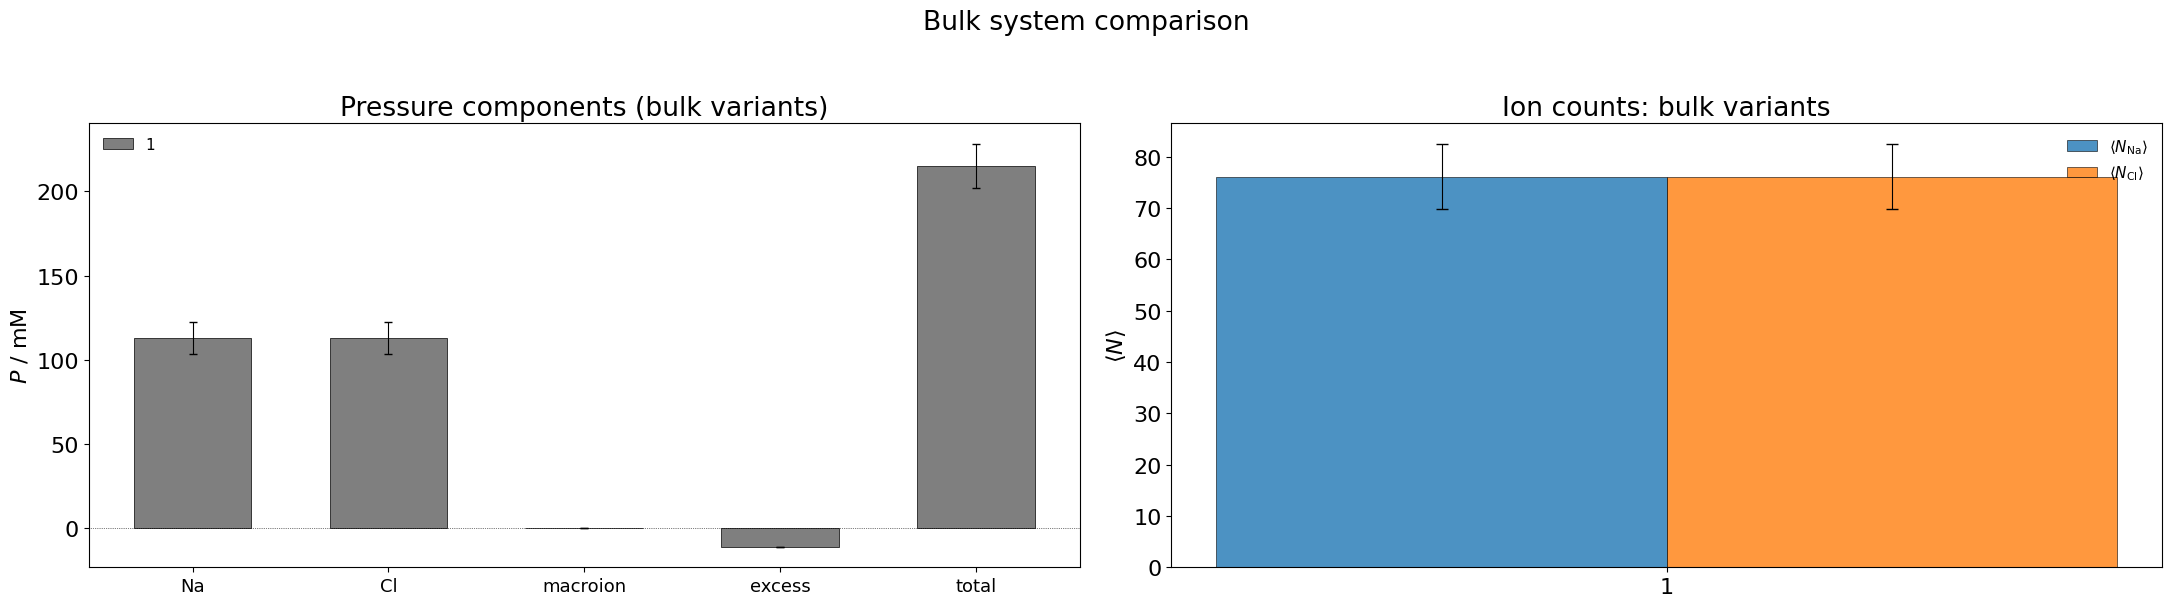

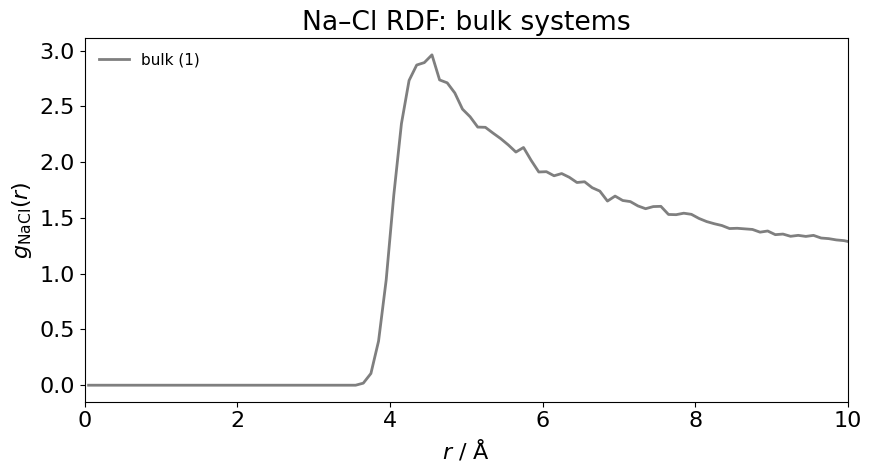

In [7]:
%cd -q $workdir

# Ion counts for the bulk system (derived from mean molarity × box volume).
_cell = bulk["cell"]
_V = _cell[0] * _cell[1] * _cell[2]  # Å³
_N_A = 6.022e23
_to_count = lambda c: c * _V / 1e27 * _N_A  # M × Å³ → count

_bulk_na = molarity(bulk, "Na")
_bulk_cl = molarity(bulk, "Cl")

print(f"Bulk box volume : {_V:.2f} Å³  ({_V/1e27*1000:.4f} L)")
print(f"⟨N_Na⟩ = {_to_count(_bulk_na):.1f}")
print(f"⟨N_Cl⟩ = {_to_count(_bulk_cl):.1f}")

# ── Bulk system comparison: pressure + ion counts ────────────────────────────

_bulk_dirs = sim_dirs[sim_dirs['type'] == 'bulk'].copy()
_suffix_color = {'C_1000': 'tab:gray', 'C_1001': 'tab:green', 'FG_50': 'tab:cyan', 'FG_51': 'tab:red', 'FG_40': 'tab:purple'}

# Pressure breakdown for each bulk system
_bulk_pressure = []
for _, _row in _bulk_dirs.iterrows():
    try:
        _p = pressureBreakdown(os.path.join(_row['dir'], 'output.yaml'))
        _bulk_pressure.append({**_p, 'suffix': _row['suffix'], 'replicate': _row['replicate']})
    except Exception:
        continue

_bulk_p_df = pd.DataFrame(_bulk_pressure)

_comps = ['Na', 'Cl', 'macroion', 'excess', 'total']
_err_comps = ['Na_err', 'Cl_err', 'macroion_err', 'excess_err', 'total_err']

# Ion counts from molarity × cell volume for each bulk system
_bulk_counts = []
for _, _row in _bulk_dirs.iterrows():
    try:
        _j = loadOutput(os.path.join(_row['dir'], 'output.yaml'))
        _cell_j = _j['cell']
        _Vj = _cell_j[0] * _cell_j[1] * _cell_j[2]
        _fac = _Vj / 1e27 * 6.022e23
        _bulk_counts.append({
            'suffix': _row['suffix'], 'replicate': _row['replicate'],
            'N_Na': molarity(_j, 'Na') * _fac,
            'N_Na_err': molarity_std(_j, 'Na') * _fac,
            'N_Cl': molarity(_j, 'Cl') * _fac,
            'N_Cl_err': molarity_std(_j, 'Cl') * _fac,
        })
    except Exception:
        continue

_bulk_count_df = pd.DataFrame(_bulk_counts)

# --- Plot ---
_x_p = np.arange(len(_comps))
_n_bulk = len(_bulk_p_df)
_width_p = 0.6 / max(_n_bulk, 1)

fig, axes = plt.subplots(1, 2, figsize=(22, 6))

# Left: absolute pressure components for each bulk system
ax = axes[0]
for _i, (_, _row) in enumerate(_bulk_p_df.iterrows()):
    _off = (_i - _n_bulk / 2 + 0.5) * _width_p
    ax.bar(_x_p + _off, [_row[c] for c in _comps], _width_p,
           yerr=[_row[ec] for ec in _err_comps], capsize=3,
           color=_suffix_color.get(_row['suffix'], 'tab:gray'),
           label=_row['suffix'], edgecolor='black', linewidth=0.5,
           error_kw=dict(elinewidth=0.8, ecolor='black'))
ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xticks(_x_p)
ax.set_xticklabels(_comps, fontsize=13)
ax.set_ylabel(r'$P$ / mM')
ax.legend(loc='upper left', frameon=False, fontsize=11)
ax.set_title('Pressure components (bulk variants)')

# Right: ion counts (Na and Cl grouped by suffix)
ax = axes[1]
_xs = np.arange(len(_bulk_count_df))
_w = 0.35
for _j_idx, (_ion, _col, _ecol, _clr) in enumerate([
        ('Na', 'N_Na', 'N_Na_err', 'tab:blue'),
        ('Cl', 'N_Cl', 'N_Cl_err', 'tab:orange'),
]):
    _off = (_j_idx - 0.5) * _w
    ax.bar(_xs + _off, _bulk_count_df[_col], _w,
           yerr=_bulk_count_df[_ecol], capsize=4,
           color=_clr, alpha=0.8,
           label=rf'$\langle N_{{\mathrm{{{_ion}}}}}\rangle$',
           edgecolor='black', linewidth=0.5,
           error_kw=dict(elinewidth=0.8, ecolor='black'))
ax.set_xticks(_xs)
ax.set_xticklabels(_bulk_count_df['suffix'].tolist())
ax.set_ylabel(r'$\langle N \rangle$')
ax.legend(frameon=False, fontsize=11)
ax.set_title('Ion counts: bulk variants')

plt.suptitle('Bulk system comparison', y=1.02)
plt.tight_layout()

# ── Bulk Na–Cl RDF ───────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
for _, _row in sim_dirs[sim_dirs['type'] == 'bulk'].iterrows():
    _rdf_path = os.path.join(_row['dir'], 'rdf-nacl.csv')
    if not os.path.exists(_rdf_path):
        continue
    _df_rdf = pd.read_csv(_rdf_path)
    ax.plot(_df_rdf['r'], _df_rdf['g(r)'],
            color=_suffix_color.get(_row['suffix'], 'tab:gray'),
            ls=rep_ls(_row['replicate']), lw=2,
            label=f"bulk ({_row['suffix']})")

ax.set_xlabel(r'$r$ / Å')
ax.set_ylabel(r'$g_{\mathrm{NaCl}}(r)$')
ax.set_xlim(0, 10)
ax.legend(loc='upper left', frameon=False, fontsize=11)
plt.title('Na–Cl RDF: bulk systems')
plt.tight_layout()


## Simulation type comparison

Compare thermodynamic and structural observables across simulation types
(isotropic, dipolar, neutral) against the bulk reference.
Folders ending in `_2` are independent replicates (shown with hatching / dashed lines).


In [8]:
%cd -q $workdir

# Compute pressure breakdown for every discovered simulation dir.
pressure_data = []
for _, row in sim_dirs.iterrows():
    try:
        p = pressureBreakdown(os.path.join(row['dir'], 'output.yaml'))
    except Exception as e:
        print(f"Skipping {row['dir']}: {e}")
        continue
    pressure_data.append({**p, 'type': row['type'], 'suffix': row['suffix'], 'replicate': row['replicate']})

pressure_df = pd.DataFrame(pressure_data)

# Single bulk reference (replicate 1 = alphabetically first bulk suffix).
bulk_ref_row = pressure_df[(pressure_df['type'] == 'bulk') & (pressure_df['replicate'] == 1)].iloc[0]

err_cols = ['Na_err', 'Cl_err', 'macroion_err', 'excess_err', 'total_err']

delta_rows = []
for _, row in pressure_df[pressure_df['type'] != 'bulk'].iterrows():
    d = {k: row[k] - bulk_ref_row[k] for k in ('Na', 'Cl', 'macroion', 'excess', 'total')}
    # error propagation on the delta: sqrt(sim_err^2 + ref_err^2)
    for ec in err_cols:
        d[ec] = (row[ec]**2 + bulk_ref_row[ec]**2) ** 0.5
    d['label'] = row['suffix']
    d['type'] = row['type']
    d['suffix'] = row['suffix']
    d['replicate'] = row['replicate']
    delta_rows.append(d)

delta_df = pd.DataFrame(delta_rows).set_index('label')
pd.set_option('display.precision', 1)
delta_df[['Na', 'Cl', 'macroion', 'excess', 'total']]


,Na,Cl,macroion,excess,total
label,,,,,
1,42.1,-76.8,14.9,129.5,109.7
1,41.9,-77.0,14.9,99.5,79.3


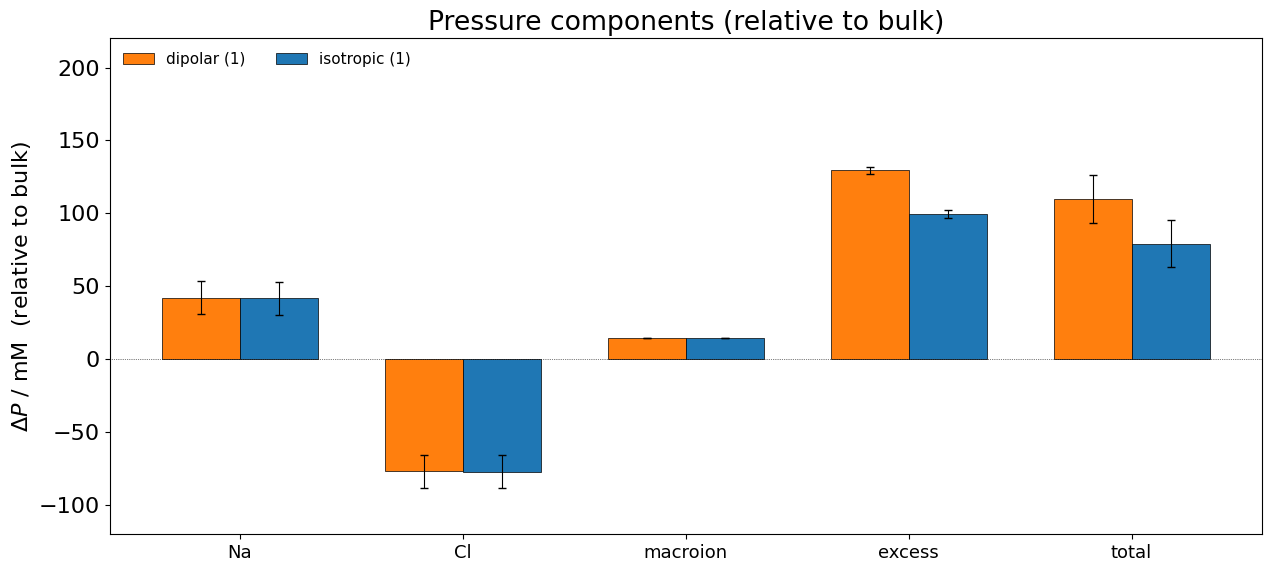

In [9]:
%cd -q $workdir

type_color_p = {'dipolar': 'tab:orange', 'isotropic': 'tab:blue', 'neutral': 'tab:purple'}
suffix_hatches = ['', '//', 'xx', '\\\\', '..']

comps     = ['Na', 'Cl', 'macroion', 'excess', 'total']
err_comps = ['Na_err', 'Cl_err', 'macroion_err', 'excess_err', 'total_err']

# Build dynamic series from sim_dirs (all non-bulk entries)
non_bulk = sim_dirs[sim_dirs['type'] != 'bulk'].copy()
series = [(r['type'], r['suffix'], r['replicate']) for _, r in non_bulk.iterrows()]

n_series = len(series)
width = 0.7 / n_series
x = np.arange(len(comps))

plot_rows = delta_df.reset_index()

# Map suffix → consistent hatch across types
all_suffixes = sorted(non_bulk['suffix'].unique())
suffix_hatch = {s: suffix_hatches[i % len(suffix_hatches)] for i, s in enumerate(all_suffixes)}

fig, ax = plt.subplots(figsize=(13, 6))

for i, (sim_type, suffix, rep) in enumerate(series):
    mask = (plot_rows['type'] == sim_type) & (plot_rows['suffix'] == suffix)
    if not mask.any():
        continue
    row = plot_rows[mask].iloc[0]
    values = [row[c] for c in comps]
    errors = [row[c] for c in err_comps]
    offset = (i - n_series / 2 + 0.5) * width
    label = f"{sim_type} ({suffix})"
    ax.bar(x + offset, values, width, yerr=errors, capsize=3,
           color=type_color_p[sim_type], hatch=suffix_hatch[suffix],
           alpha=rep_alpha(rep), label=label,
           edgecolor='black', linewidth=0.5,
           error_kw=dict(elinewidth=0.8, ecolor='black'))

ax.axhline(0, color='k', lw=0.5, ls=':')
ax.set_xticks(x)
ax.set_xticklabels(comps, fontsize=13)
ax.set_ylim(-120,220)
ax.set_ylabel(r'$\Delta P$ / mM  (relative to bulk)')
ax.legend(loc='upper left', frameon=False, fontsize=11, ncol=2)
plt.title('Pressure components (relative to bulk)')
plt.tight_layout()


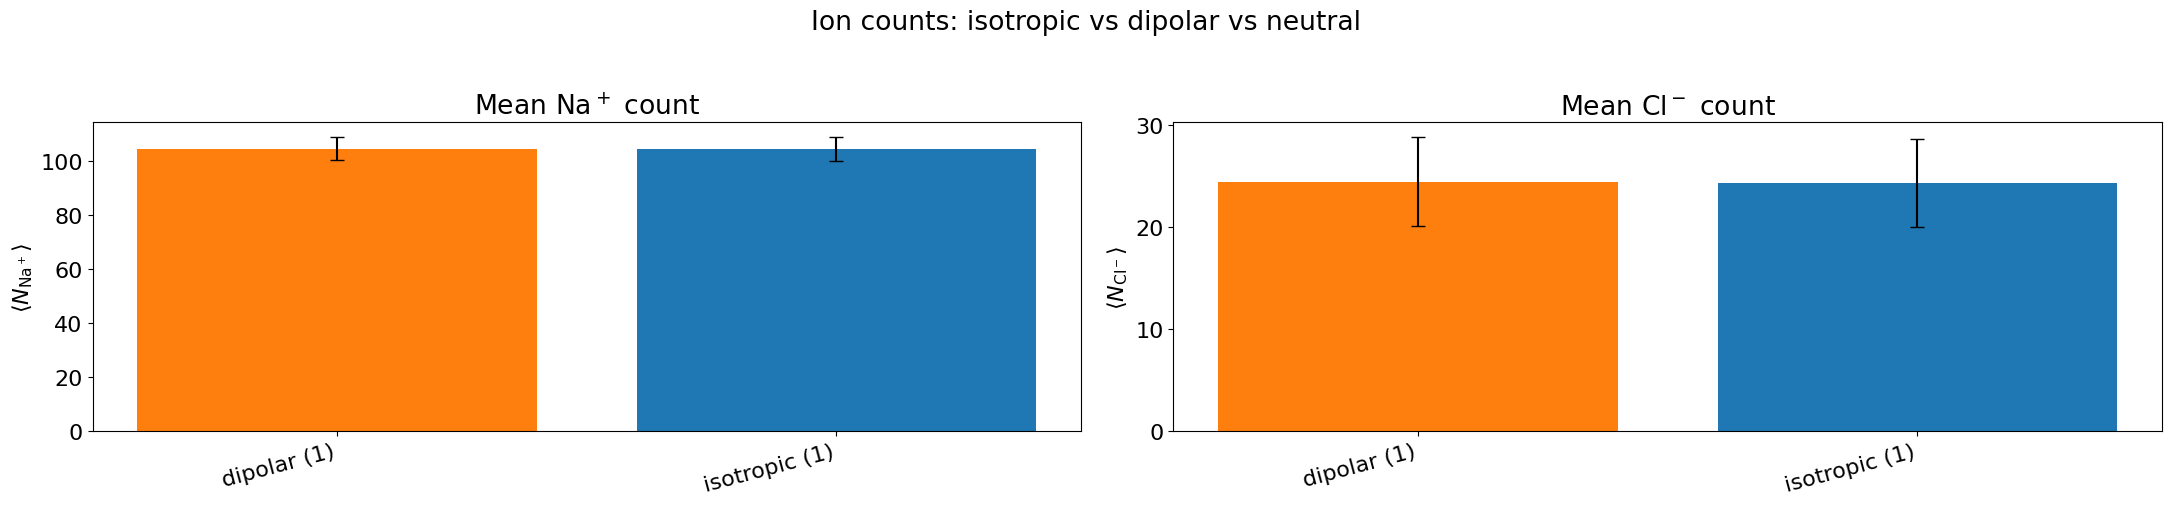

In [10]:
%cd -q $workdir

def ionCount(j, atomtype):
    """Mean and std of ion count from CollectiveVariable Count analysis."""
    cv = findAnalysis(
        j, 'collectivevariable',
        property='Count',
        description=f'selection: atomtype {atomtype}',
    )
    if cv is None:
        return None, None
    mean = cv['mean']
    std = (cv['rms']**2 - mean**2)**0.5  # sqrt(⟨N²⟩ - ⟨N⟩²)
    return mean, std

count_rows = []
for _, row in sim_dirs[sim_dirs['type'] != 'bulk'].iterrows():
    try:
        j = loadOutput(os.path.join(row['dir'], 'output.yaml'))
    except Exception:
        continue
    for ion in ('Na', 'Cl'):
        mean, std = ionCount(j, ion)
        if mean is None:
            continue
        count_rows.append({
            'ion': ion,
            'type': row['type'], 'suffix': row['suffix'], 'replicate': row['replicate'],
            'mean': mean, 'std': std,
        })

count_df = pd.DataFrame(count_rows)

hatches = ['', '//', 'xx', '\\\\', '..']
type_color = {'isotropic': 'tab:blue', 'dipolar': 'tab:orange', 'neutral': 'tab:purple'}

fig, axes = plt.subplots(1, 2, figsize=(22, 5), sharey=False)

for ax, ion in zip(axes, ['Na', 'Cl']):
    df_ion = count_df[count_df['ion'] == ion].reset_index(drop=True)
    if df_ion.empty:
        continue
    xlabels = [f"{row['type']} ({row['suffix']})" for _, row in df_ion.iterrows()]
    colors = [type_color.get(row['type'], 'tab:gray') for _, row in df_ion.iterrows()]
    x = np.arange(len(xlabels))
    bars = ax.bar(x, df_ion['mean'], yerr=df_ion['std'], capsize=5, color=colors)
    for bar, rep in zip(bars, df_ion['replicate']):
        bar.set_alpha(rep_alpha(rep))
        bar.set_hatch(hatches[(rep - 1) % len(hatches)])
    ax.set_xticks(x)
    ax.set_xticklabels(xlabels, rotation=15, ha='right')

axes[0].set_ylabel(r'$\langle N_{\mathrm{Na}^+} \rangle$')
axes[1].set_ylabel(r'$\langle N_{\mathrm{Cl}^-} \rangle$')
axes[0].set_title(r'Mean Na$^+$ count')
axes[1].set_title(r'Mean Cl$^-$ count')
plt.suptitle('Ion counts: isotropic vs dipolar vs neutral', y=1.02)
plt.tight_layout()


In [11]:
%cd -q $workdir

ionic_rows = []
for _, row in sim_dirs.iterrows():
    try:
        j = loadOutput(os.path.join(row['dir'], 'output.yaml'))
    except Exception:
        continue
    ionic_rows.append({
        'label': f"{row['type']} ({row['suffix']})",
        '[Na+] / M': molarity(j, 'Na'),
        '[Cl-] / M': molarity(j, 'Cl'),
        'I / M':     ionicStrength(j),
        'λ_D / Å':   debyeLength(j),
    })

ionic_df = pd.DataFrame(ionic_rows).set_index('label')
pd.set_option('display.precision', 4)
ionic_df


,[Na+] / M,[Cl-] / M,I / M,λ_D / Å
label,,,,
bulk (1),0.1131,0.1131,0.1131,9.0365
dipolar (1),0.1553,0.0363,0.0958,9.8203
isotropic (1),0.1550,0.0361,0.0956,9.8317


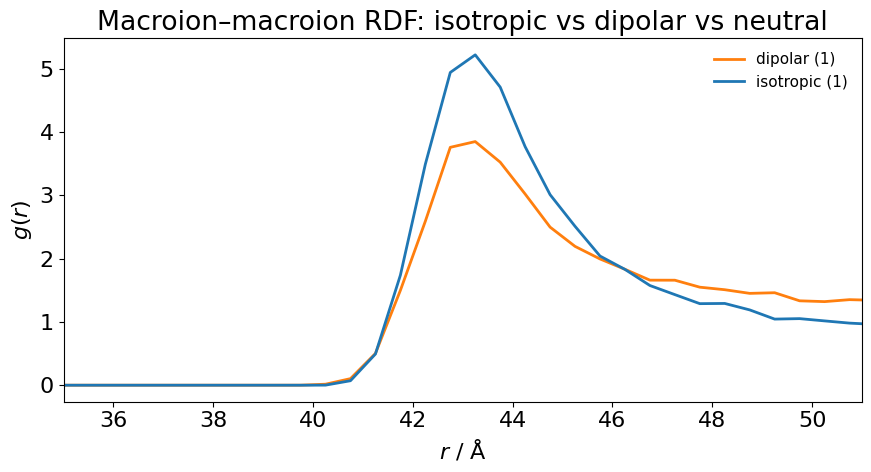

In [12]:
%cd -q $workdir

type_color  = {'isotropic': 'tab:blue', 'dipolar': 'tab:orange', 'neutral': 'tab:purple'}

fig, ax = plt.subplots(figsize=(9, 5))

for _, row in sim_dirs[sim_dirs['type'].isin(['isotropic', 'dipolar', 'neutral'])].iterrows():
    rdf_path = os.path.join(row['dir'], 'rdf.csv')
    if not os.path.exists(rdf_path):
        continue
    df = pd.read_csv(rdf_path)
    label = f"{row['type']} ({row['suffix']})"
    ax.plot(df['r'], df['g(r)'],
            color=type_color[row['type']], ls=rep_ls(row['replicate']),
            lw=2, alpha=rep_alpha(row['replicate']), label=label)

ax.set_xlabel(r'$r$ / Å')
ax.set_ylabel(r'$g(r)$')
ax.set_xlim(35, 51)
ax.legend(loc="upper right", frameon=False, fontsize=11)
plt.title('Macroion–macroion RDF: isotropic vs dipolar vs neutral')
plt.tight_layout()


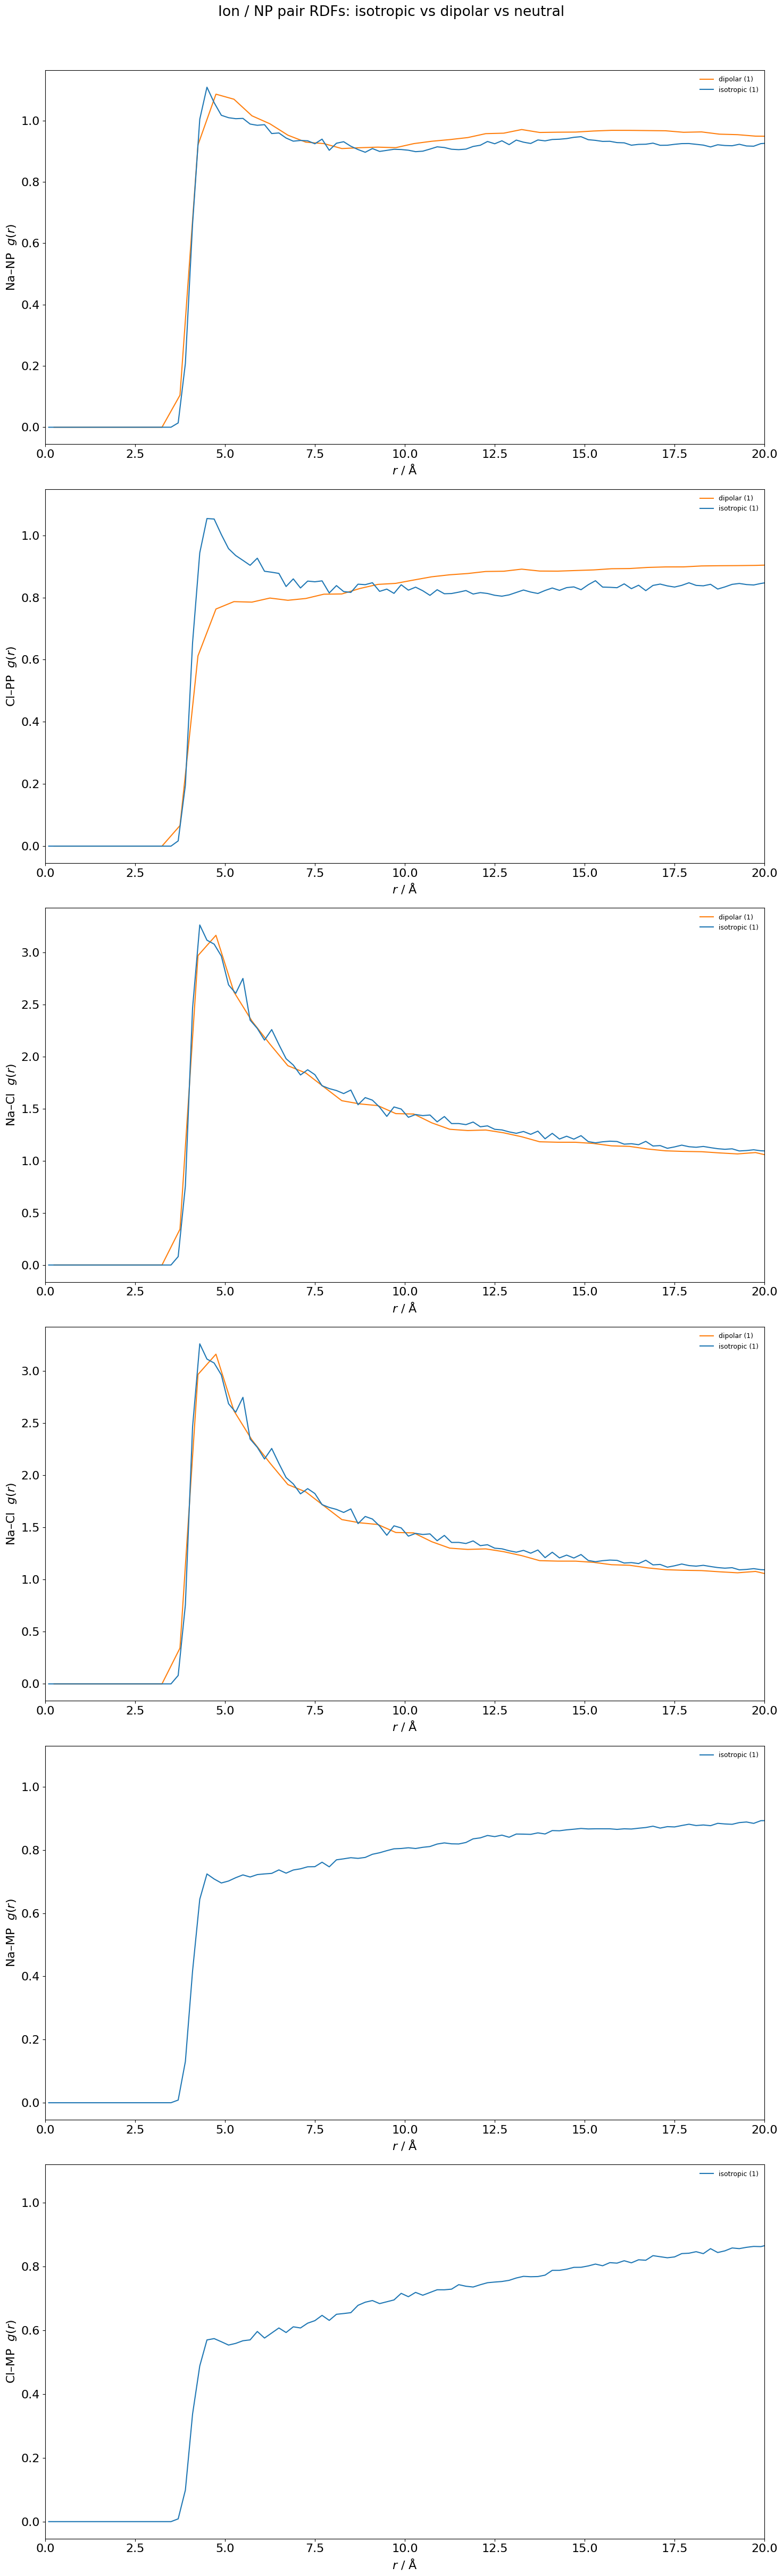

In [15]:
%cd -q $workdir

rdf_files = [
    ('Na–NP',        'rdf-na-np.csv'),
    ('Cl–PP',        'rdf-cl-pp.csv'),
    ('Na–Cl',        'rdf-na-cl.csv'),
    ('Na–Cl',        'rdf-na-cl.csv'),
    ('Na–MP',        'rdf-na-mp.csv'),
    ('Cl–MP',        'rdf-cl-mp.csv'),
]

type_color = {'isotropic': 'tab:blue', 'dipolar': 'tab:orange', 'neutral': 'tab:purple'}

fig, axes = plt.subplots(len(rdf_files), 1, figsize=(15, 8 * len(rdf_files)), sharex=False)

for ax, (rdf_label, rdf_file) in zip(axes, rdf_files):
    for _, row in sim_dirs[sim_dirs['type'].isin(['isotropic', 'dipolar', 'neutral'])].iterrows():
        rdf_path = os.path.join(row['dir'], rdf_file)
        if not os.path.exists(rdf_path):
            continue
        df = pd.read_csv(rdf_path)
        label = f"{row['type']} ({row['suffix']})"
        ax.plot(df['r'], df['g(r)'],
                color=type_color[row['type']], ls=rep_ls(row['replicate']),
                lw=1.5, alpha=rep_alpha(row['replicate']), label=label)
    ax.set_ylabel(rdf_label + r'  $g(r)$')
    ax.set_xlabel(r'$r$ / Å')
    ax.set_xlim(0,20)
    ax.legend(loc=0, frameon=False, fontsize=9)

# Add bulk Na–Cl reference to the last subplot
bulk_nacl_path = os.path.join(workdir, 'bulk_C_1000', 'rdf-nacl.csv')
if os.path.exists(bulk_nacl_path):
    df_bulk = pd.read_csv(bulk_nacl_path)
    axes[-1].plot(df_bulk['r'], df_bulk['g(r)'],
                  color='tab:gray', ls='-', lw=1.5)#, label='bulk')
    #axes[-1].legend(loc="upper right", frameon=False, fontsize=9)

plt.suptitle('Ion / NP pair RDFs: isotropic vs dipolar vs neutral', y=1.01)
plt.tight_layout()


## Energy convergence

Plot total energy vs. MC step for each simulation to check equilibration.
The first 10% of steps are discarded as equilibration.

> **Note:** observables from `output.yaml` (pressure, molarity, ion counts, RDFs) are
> running averages accumulated by faunus over the full run and cannot be retroactively
> trimmed here. To exclude equilibration from those quantities, run a short
> equilibration simulation first and then start the production run from its final state.

/tmp/ipykernel_318091/529269669.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, fontsize=10)


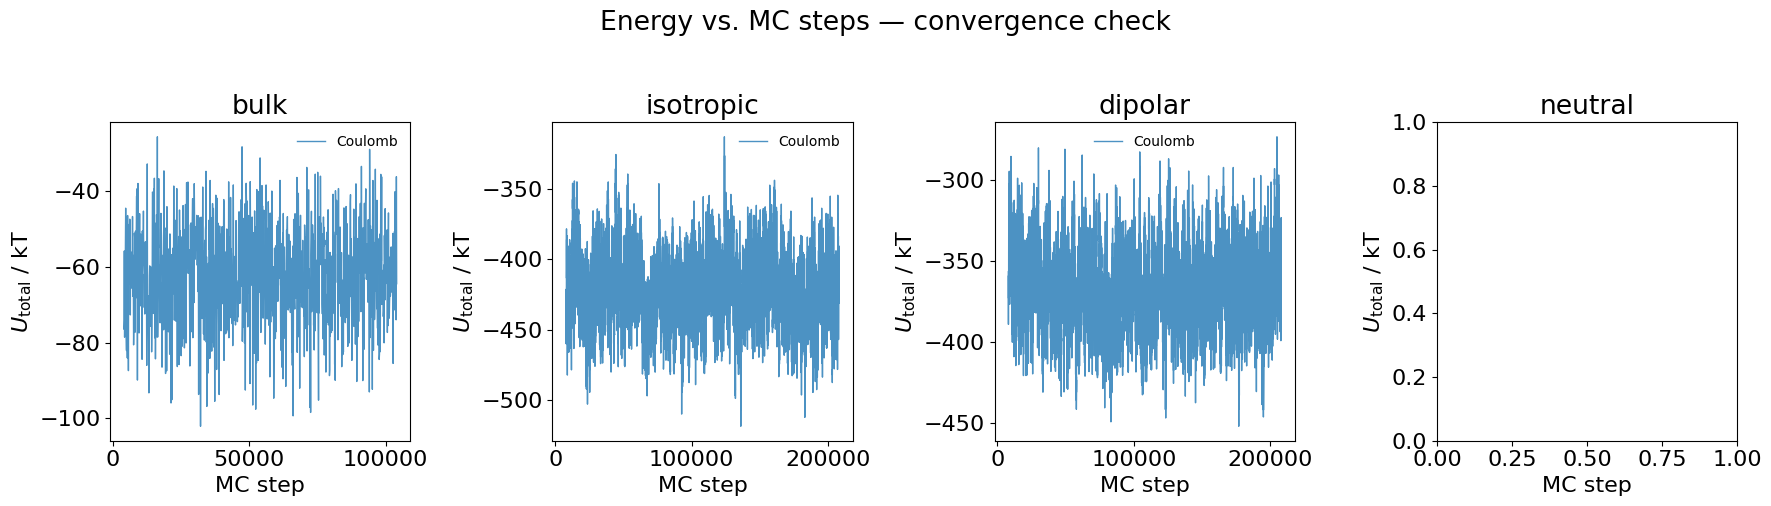

In [16]:
%cd -q $workdir

import itertools

sim_types = ['bulk', 'isotropic', 'dipolar', 'neutral']
_palette = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharey=False)

for ax, sim_type in zip(axes, sim_types):
    subset = sim_dirs[sim_dirs['type'] == sim_type]
    for _, row in subset.iterrows():
        energy_path = os.path.join(row['dir'], 'energy.csv.gz')
        if not os.path.exists(energy_path):
            continue
        df = pd.read_csv(energy_path)
        rep = row['replicate']
        color = _palette[(rep - 1) % len(_palette)]
        label = "Coulomb" if rep == 1 else f"Fanougakis"
        ax.plot(df['step'], df['total'],
                color=color, ls=rep_ls(rep),
                lw=1, alpha=0.8, label=label)
    ax.set_xlabel('MC step')
    ax.set_ylabel(r'$U_\mathrm{total}$ / kT')
    ax.set_title(sim_type)
    ax.legend(frameon=False, fontsize=10)

plt.suptitle('Energy vs. MC steps — convergence check', y=1.02)
plt.tight_layout()
